# 02 — Exploratory data analysis

**Question this notebook answers:** what separates malignant from benign in these
measurements, and how much genuinely independent information do 30 columns carry?

The point is not to plot every column. It is to answer three questions whose answers
change what gets modelled in notebook 03:

1. Which measurements separate the classes, and which are noise?
2. Are the "mean", "SE" and "worst" aggregations telling us different things?
3. How redundant are the features — and does that redundancy matter for the model choice?

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import data as D
from src import profiling as P
from src import figures as F

pd.set_option("display.width", 160, "display.max_columns", 40)
frame = D.load()
X, y = D.xy(frame)
print(f"{len(frame)} patients, {len(D.feature_columns(frame))} features, "
      f"{y.mean():.1%} malignant")

569 patients, 30 features, 37.3% malignant


## Class balance and the scale problem

Two facts that constrain everything downstream, in one figure.

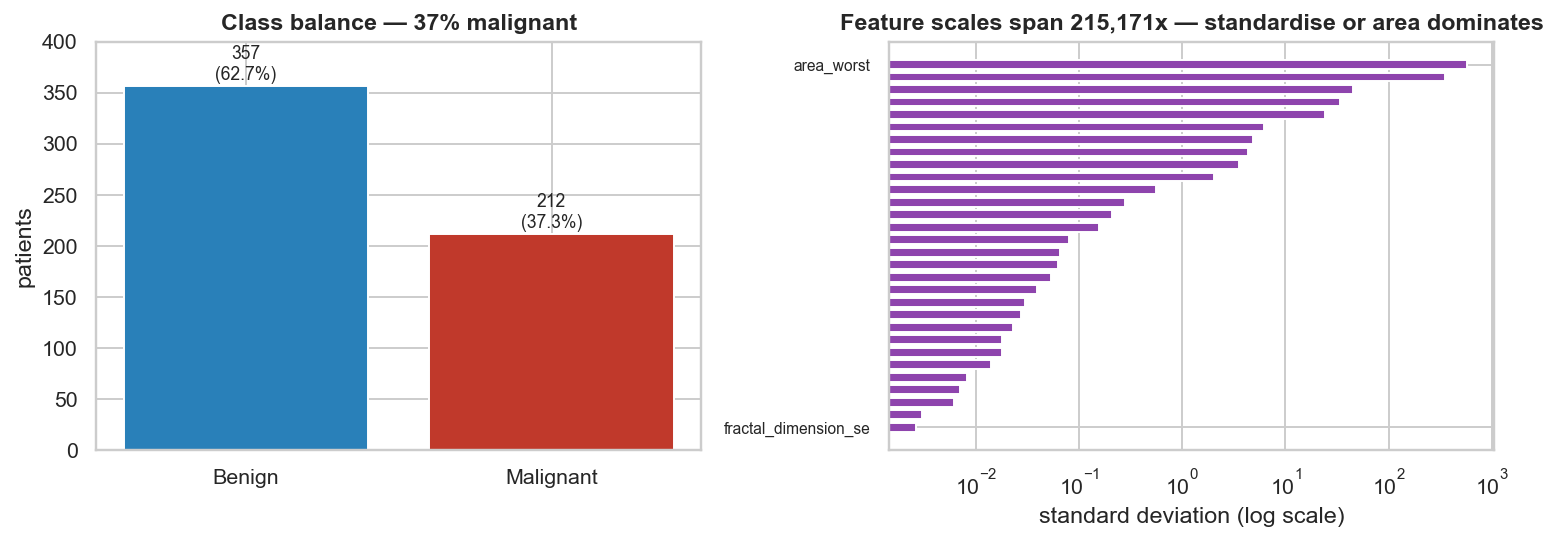

In [2]:
F.class_balance_and_scale(frame)
from IPython.display import Image
Image("../outputs/figures/01_class_balance_and_scale.png")

37% malignant is a mild imbalance — enough to require stratification, not enough to
need resampling. Accuracy still has a meaningful floor: **a model predicting "benign"
for everyone scores 62.6%**, which is the number any reported accuracy has to be read
against.

The right panel is the reason `StandardScaler` sits in every pipeline. The largest
feature standard deviation is roughly 215,000 times the smallest.

## Which measurements actually separate the classes?

Ranked by univariate AUC — the probability that a randomly chosen malignant case scores
higher than a randomly chosen benign one. AUC rather than a t-statistic because several
of these features are strongly right-skewed, and AUC is rank-based, so it does not
assume normality. Mann-Whitney supplies the p-value for the same reason, and
Benjamini-Hochberg adjusts it for the fact that we are running 30 correlated tests on
one dataset.

In [3]:
separation = P.univariate_separation(frame)
separation.head(10).style.format({"auc": "{:.4f}", "cohens_d": "{:.3f}",
                                  "p_value": "{:.2e}", "p_adjusted": "{:.2e}"})

,feature,auc,cohens_d,p_value,statistic,p_adjusted
0,perimeter_worst,0.9755,2.598,2.58e-80,worst,7.75e-79
1,radius_worst,0.9704,2.544,1.14e-78,worst,1.70e-77
2,area_worst,0.9698,2.230,1.80e-78,worst,1.80e-77
3,concave_points_worst,0.9667,2.693,1.86e-77,worst,1.40e-76
4,concave_points_mean,0.9644,2.545,1.01e-76,mean,6.04e-76
5,perimeter_mean,0.9469,2.290,3.55e-71,mean,1.78e-70
6,area_mean,0.9383,2.076,1.54e-68,mean,6.60e-68
7,concavity_mean,0.9378,2.003,2.16e-68,mean,8.12e-68
8,radius_mean,0.9375,2.205,2.69e-68,mean,8.98e-68
9,area_se,0.9264,1.353,5.77e-65,se,1.73e-64


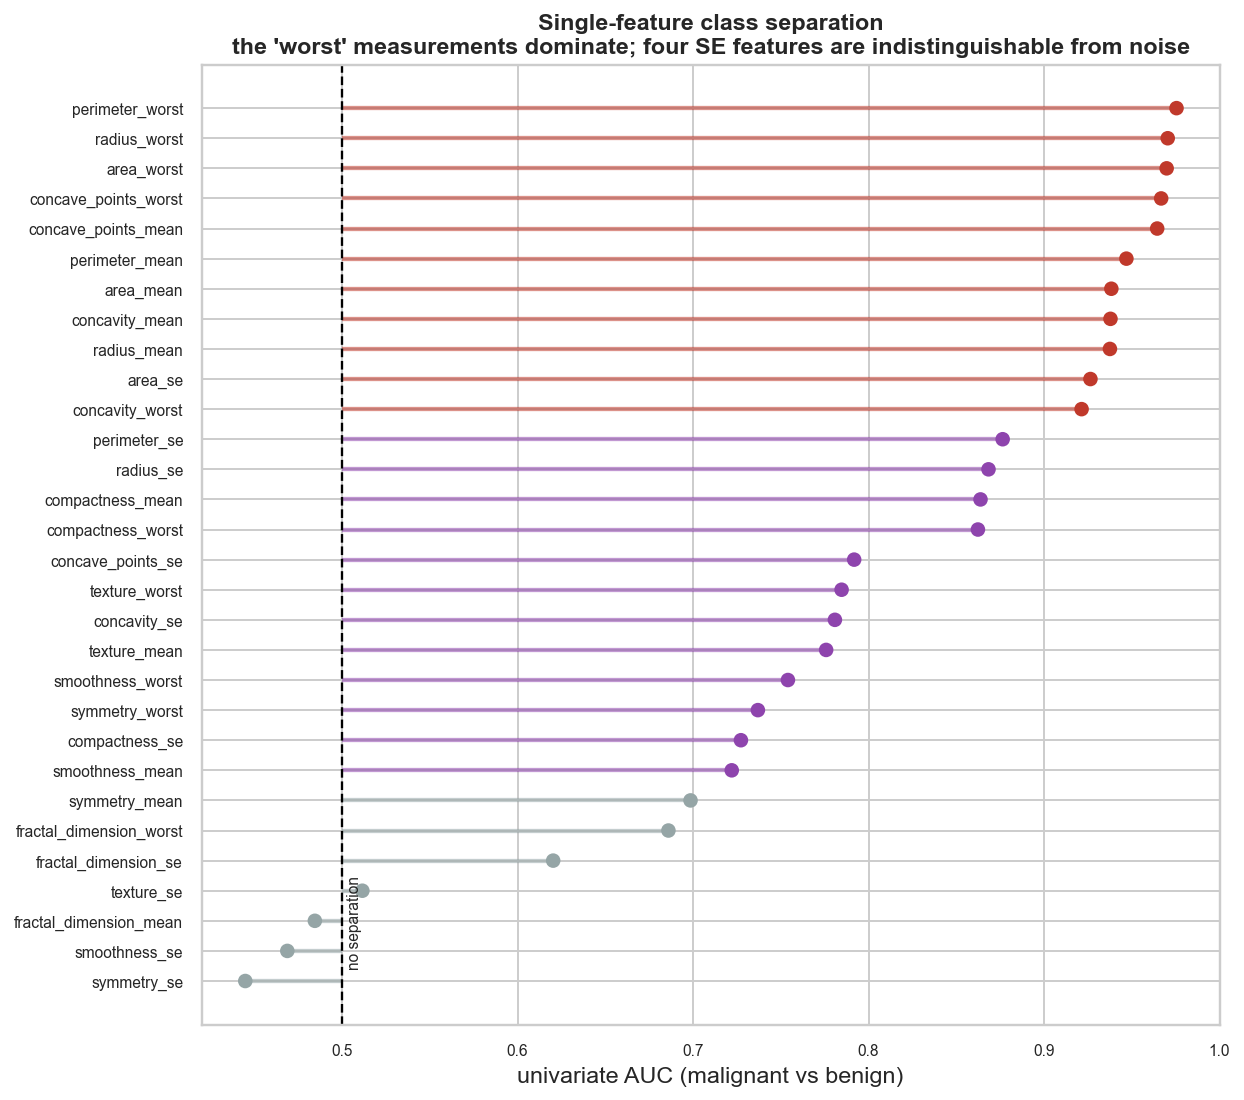

In [4]:
F.univariate_separation(separation)
Image("../outputs/figures/03_univariate_separation.png")

Three things fall out of this ranking.

**The "worst" aggregation dominates.** Four of the top five features are `_worst`
measurements. That is clinically sensible rather than a quirk: the "worst" value is the
mean of the three largest nuclei in the image, and malignancy is characterised by *some*
nuclei being grossly abnormal, not by the average nucleus shifting. Averaging over a
whole image dilutes exactly the signal that matters. This shows up again, decisively, in
the feature-set comparison in notebook 03.

**Size and outline irregularity carry the signal.** `perimeter_worst` (AUC 0.976),
`radius_worst`, `area_worst`, and `concave_points_worst` lead. Malignant nuclei are
larger and their contours are more indented.

**Four features are indistinguishable from noise.**

In [5]:
separation.tail(5).style.format({"auc": "{:.4f}", "cohens_d": "{:.3f}",
                                 "p_value": "{:.3f}", "p_adjusted": "{:.3f}"})

,feature,auc,cohens_d,p_value,statistic,p_adjusted
25,fractal_dimension_se,0.6203,0.161,0.000,se,0.000
26,texture_se,0.5116,-0.017,0.644,se,0.644
27,fractal_dimension_mean,0.4845,-0.027,0.537,mean,0.556
28,smoothness_se,0.4688,-0.139,0.214,se,0.229
29,symmetry_se,0.4449,-0.013,0.028,se,0.031


`texture_se`, `fractal_dimension_mean`, `smoothness_se` and `symmetry_se` all sit at
or below AUC 0.51 and do not survive multiple-testing correction. Note that three of the
four are SE columns — the *variability* of a measurement across nuclei carries far less
information than its level.

`symmetry_se` is worth a second look: raw p = 0.028 would pass a naive 0.05 threshold,
but its AUC is 0.445 — i.e. *benign* cases score marginally higher, and after BH
correction (p = 0.031) it remains borderline on a directionally uninteresting effect.
This is precisely what testing 30 features and reading the raw p-values would get wrong.

## Where the classes overlap

AUC of 0.97 is not separation. The distributions of even the best features overlap, and
the overlap region is where every error in this project lives.

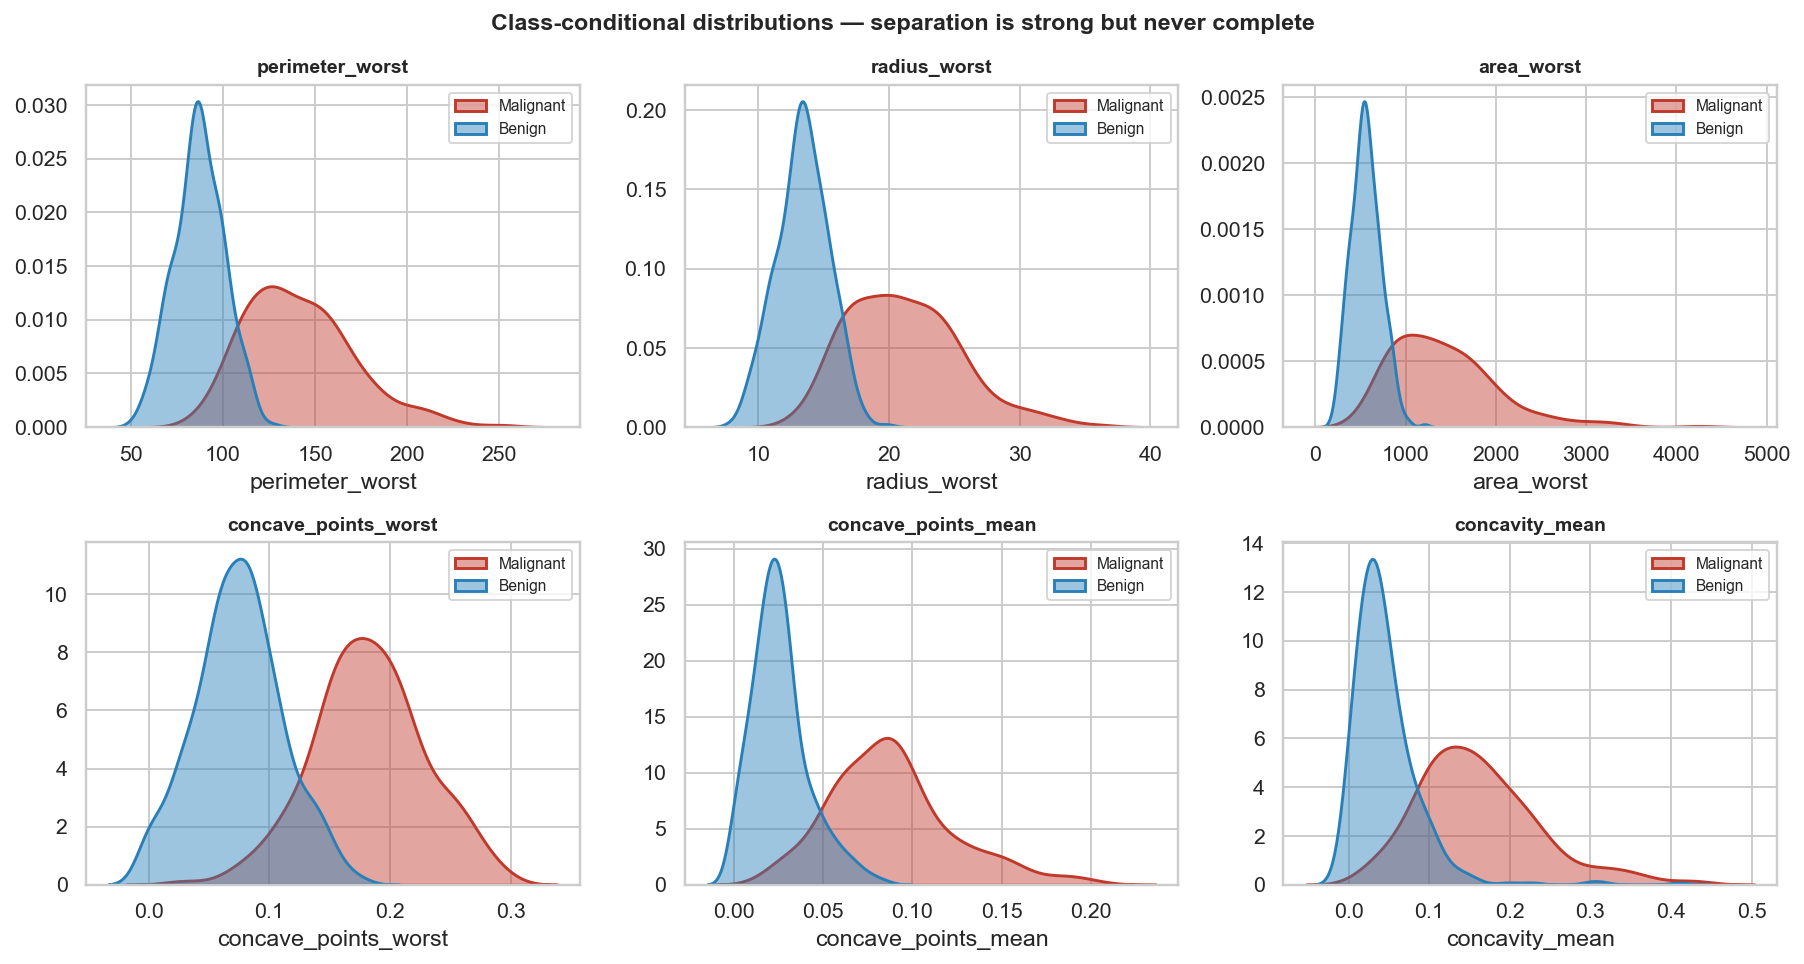

In [6]:
top = separation.head(5)["feature"].tolist() + ["concavity_mean"]
F.feature_distributions(frame, top)
Image("../outputs/figures/04_feature_distributions.png")

Note the spike at exactly zero in the `concavity_mean` panel — those are the 13
benign cases from notebook 01, visible as a structural feature of the data rather than
as an artefact.

Every panel shows a benign right tail sitting under the malignant distribution. Those
patients are the false positives and false negatives, and no choice of classifier
removes them — only the threshold decides which of the two errors they become.

## How redundant are the 30 features?

This is the question with the most consequence for model choice. Start with the part
that is not empirical at all.

In [7]:
collin = P.collinearity(frame)
for statistic, identities in collin["geometric_identities"].items():
    print(f"{statistic:6s}  corr(area, pi*r^2) = {identities['area_vs_pi_r_squared']:.4f}"
          f"   corr(perimeter, 2*pi*r) = {identities['perimeter_vs_2_pi_r']:.4f}")

mean    corr(area, pi*r^2) = 0.9991   corr(perimeter, 2*pi*r) = 0.9979
worst   corr(area, pi*r^2) = 0.9981   corr(perimeter, 2*pi*r) = 0.9937


**`radius`, `perimeter` and `area` are one measurement written three ways.** For an
approximately circular nucleus, area = πr² and perimeter = 2πr *by definition*. The
correlations above 0.99 are not a discovery about tumours; they are geometry. Six of the
30 columns (three statistics × three size measures) are near-deterministic functions of
each other.

That is the extreme case. The general picture:

In [8]:
print(f"Correlated pairs: {collin['pairs_above_0.9']} above r=0.9, "
      f"{collin['pairs_above_0.8']} above r=0.8, out of {collin['total_pairs']} pairs")
print()
print("Highest variance inflation factors:")
print(collin["vif"].head(8).round(1).to_string())
print()
print(f"VIF > 10: {collin['vif_above_10']} of 30 features")
print(f"VIF >  5: {collin['vif_above_5']} of 30 features")

Correlated pairs: 21 above r=0.9, 44 above r=0.8, out of 435 pairs

Highest variance inflation factors:
radius_mean        3806.1
perimeter_mean     3786.4
radius_worst        799.1
perimeter_worst     405.0
area_mean           347.9
area_worst          337.2
radius_se            75.5
concavity_mean       70.8

VIF > 10: 23 of 30 features
VIF >  5: 27 of 30 features


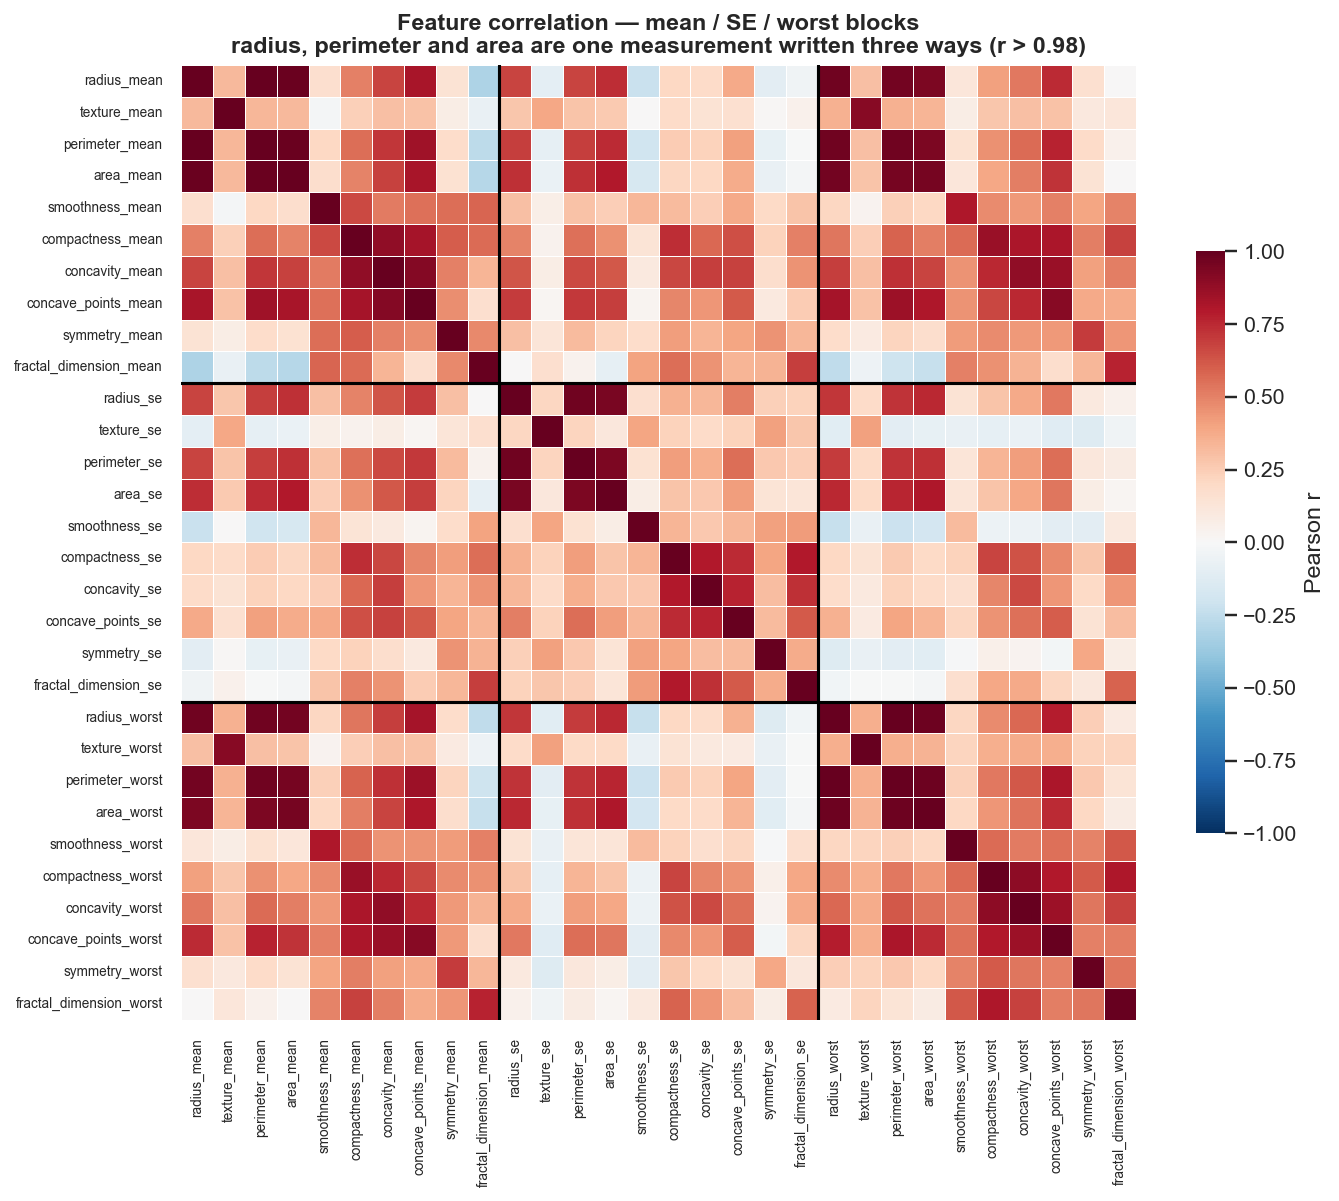

In [9]:
F.correlation_structure(frame)
Image("../outputs/figures/02_correlation_structure.png")

**23 of 30 features have a VIF above 10**, the conventional red line, and
`radius_mean` reaches 3,806. The three black-bordered blocks in the heatmap are the
mean / SE / worst groups; the bright square in each corner is the radius-perimeter-area
cluster.

Within each base measurement, the mean and worst aggregations are also tightly coupled:

In [10]:
collin["block_correlations"].round(3)

,mean~worst,mean~se,se~worst
feature,,,
radius,0.970,0.679,0.715
texture,0.912,0.386,0.409
perimeter,0.970,0.693,0.721
area,0.959,0.800,0.811
smoothness,0.805,0.332,0.314
compactness,0.866,0.739,0.679
concavity,0.884,0.691,0.663
concave_points,0.910,0.616,0.602
symmetry,0.700,0.449,0.389


`mean ~ worst` correlations run from 0.70 to 0.97. The SE column is the most
independent of the three for almost every measurement — it is also, per the ranking
above, the least informative. Redundant and useful, or independent and uninformative:
that is the trade the feature-set comparison in notebook 03 has to resolve.

### What this implies

PCA quantifies how much independent variation there really is.

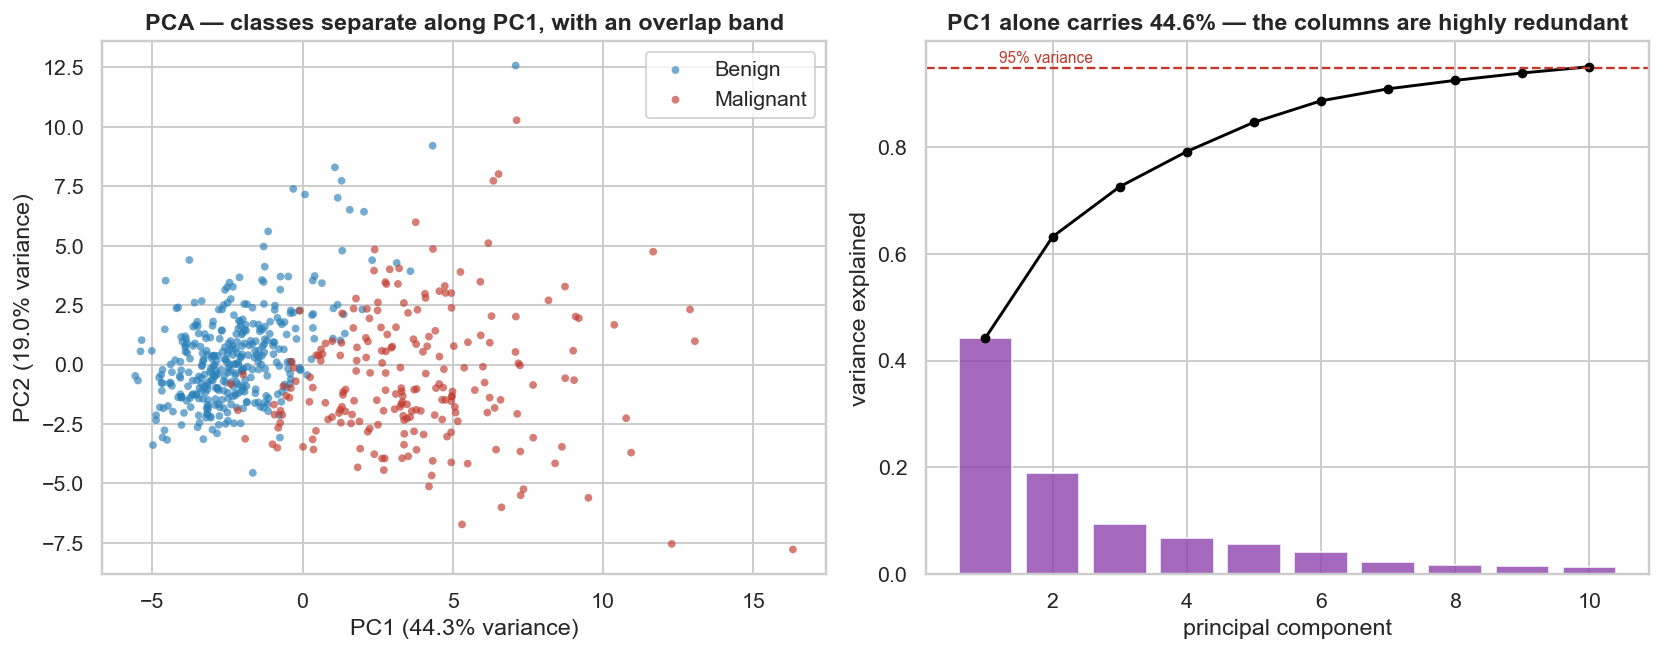

In [11]:
F.pca_projection(X, y)
Image("../outputs/figures/05_pca_projection.png")

**PC1 alone absorbs 44.6% of the variance in 30 standardised columns**, and it is
essentially a "size and irregularity" axis along which the classes largely separate. It
takes 10 components to reach 95% — so 30 columns carry roughly 10 columns' worth of
independent information, which is exactly what the mean/SE/worst construction would
predict.

Three consequences for notebook 03:

1. **Individual coefficients are not interpretable as effects.** With VIFs in the
   thousands, the model can trade weight between `radius_mean` and `perimeter_mean`
   almost freely. Coefficients get read as association, never as mechanism, and never as
   feature importance.
2. **L2 regularisation over L1 for the headline model.** L1 would arbitrarily pick one
   of each collinear cluster and zero the rest — fine for prediction, actively
   misleading if anyone reads the surviving coefficients as "the features that matter".
3. **Fewer features should cost almost nothing.** If 30 columns hold 10 columns of
   information, a well-chosen 10 should perform like all 30. That is a testable
   prediction, and notebook 03 tests it.

## What carries forward

| Finding | Consequence for modelling |
|---|---|
| `_worst` aggregations dominate the ranking | Test a worst-only feature set explicitly |
| 4 features indistinguishable from noise (3 of them SE) | Expect the SE block to underperform badly |
| Geometric identity: radius/perimeter/area are one measurement | Do not read individual coefficients as effects |
| 23/30 features with VIF > 10; 10 PCs for 95% variance | Prefer L2 over L1; expect feature reduction to be cheap |
| Class distributions overlap even on the best features | Errors are irreducible; the **threshold** decides their type |

Next: **03_modelling.ipynb** — model comparison, and the decision that actually matters.